## Ensemble

### โจทย์
- เลือก algorithm สำหรับใช้ Classification 1 ตัว โดยสามารมใช้ library ได้
- เขียน Parallel Computing ที่ builin python และ numpy ในการทำ Bagging ด้วยตัวเอง
- เขียน bosting แบบปกติได้เลย

### Import Library

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

### Import Data

In [2]:
# โหลดชุดข้อมูล Iris จากไฟล์ CSV
iris_df = pd.read_csv("data_set/Iris.csv")

# แยก Features (ตัดคอลัมน์ Id และ Species ออก เพื่อป้องกันโมเดลจำลำดับ Id)
X = iris_df[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]].to_numpy()

# แปลงชื่อสายพันธุ์ดอกไม้ (Target) จากข้อความให้เป็นตัวเลข 0, 1, 2
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(iris_df["Species"])

# ตรวจสอบขนาดข้อมูลและจำนวนตัวอย่างในแต่ละคลาส
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Classes:", list(label_encoder.classes_))
print("Class counts:", np.bincount(y))
iris_df.head()

Shape of X: (150, 4)
Shape of y: (150,)
Classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Class counts: [50 50 50]


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### Function Visualization

In [3]:
# วาดตาราง Confusion Matrix พร้อมตัวเลขจำนวนตัวอย่างในแต่ละช่อง
def plot_confusion_matrix_ax(ax, y_true, y_pred, class_names, title, cmap_name="Blues"):
    """ฟังก์ชันวาด Confusion Matrix ลงบน Axes ที่กำหนด"""
    cm = confusion_matrix(y_true, y_pred)
    ax.imshow(cm, interpolation="nearest", cmap=cmap_name)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

    tick_marks = np.arange(len(class_names))
    ax.set_xticks(tick_marks)
    ax.set_yticks(tick_marks)
    ax.set_xticklabels(class_names, rotation=20, ha="right")
    ax.set_yticklabels(class_names)

    # แสดงตัวเลขจำนวนตัวอย่างในแต่ละช่องของ Confusion Matrix
    threshold = cm.max() / 2.0
    for row_index in range(cm.shape[0]):
        for col_index in range(cm.shape[1]):
            text_color = "white" if cm[row_index, col_index] > threshold else "black"
            ax.text(
                col_index,
                row_index,
                str(cm[row_index, col_index]),
                ha="center",
                va="center",
                color=text_color,
                fontsize=12,
                fontweight="bold"
            )

In [4]:
# สร้างตารางพิกัด 2 มิติ และให้โมเดลทำนายขอบเขตการแบ่งคลาส (Decision Boundary)
def create_2d_decision_grid(X_scaled, model, feature_x_index=2, feature_y_index=3, grid_step=0.05):
    """ฟังก์ชันสร้างตารางพิกัด 2 มิติ และทำนายขอบเขตการแบ่งคลาสจากโมเดล 4 มิติ"""
    x_min = X_scaled[:, feature_x_index].min() - 0.6
    x_max = X_scaled[:, feature_x_index].max() + 0.6
    y_min = X_scaled[:, feature_y_index].min() - 0.6
    y_max = X_scaled[:, feature_y_index].max() + 0.6

    grid_x, grid_y = np.meshgrid(
        np.arange(x_min, x_max, grid_step),
        np.arange(y_min, y_max, grid_step)
    )

    # สร้างข้อมูลจำลอง 4 มิติ โดยกำหนดอีก 2 Features ที่เหลือเป็น 0 (ค่าเฉลี่ยหลัง Scaling)
    grid_points = np.zeros((grid_x.size, X_scaled.shape[1]))
    grid_points[:, feature_x_index] = grid_x.ravel()
    grid_points[:, feature_y_index] = grid_y.ravel()

    grid_predictions = model.predict(grid_points).reshape(grid_x.shape)
    return grid_x, grid_y, grid_predictions

In [5]:
# แสดงผลขั้นตอนการเทรน (Decision Boundary + Support Vectors) และผลลัพธ์ชุด Train
def plot_training_visualization(X_train_scaled, y_train, y_pred_train, model, class_names):
    """ฟังก์ชันแสดงผลขั้นตอนการเทรน (Support Vectors + ขอบเขต) และผลลัพธ์สุดท้ายของชุด Train"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # กราฟซ้าย: แสดงจุดข้อมูล Train, ขอบเขตการแบ่งคลาส และ Support Vectors
    grid_x, grid_y, grid_predictions = create_2d_decision_grid(
        X_scaled=X_train_scaled,
        model=model,
        feature_x_index=2,
        feature_y_index=3,
        grid_step=0.05
    )
    axes[0].contourf(grid_x, grid_y, grid_predictions, alpha=0.25, cmap="viridis")

    for class_index, class_label in enumerate(class_names):
        class_mask = (y_train == class_index)
        axes[0].scatter(
            X_train_scaled[class_mask, 2],
            X_train_scaled[class_mask, 3],
            label=class_label,
            edgecolors="black",
            s=50
        )

    # ไฮไลต์จุดที่เป็น Support Vectors จากโมเดล SVM
    axes[0].scatter(
        model.support_vectors_[:, 2],
        model.support_vectors_[:, 3],
        s=140,
        facecolors="none",
        edgecolors="red",
        linewidths=1.5,
        label=f"Support Vectors ({len(model.support_vectors_)})"
    )
    axes[0].set_title("Training Phase: Decision Boundary & Support Vectors", fontsize=12)
    axes[0].set_xlabel("PetalLengthCm (Scaled)")
    axes[0].set_ylabel("PetalWidthCm (Scaled)")
    axes[0].legend(loc="upper left", fontsize=9)

    # กราฟขวา: แสดง Confusion Matrix ของผลลัพธ์สุดท้ายในชุด Train
    train_accuracy = accuracy_score(y_train, y_pred_train)
    plot_confusion_matrix_ax(
        ax=axes[1],
        y_true=y_train,
        y_pred=y_pred_train,
        class_names=class_names,
        title=f"Training Result Confusion Matrix (Acc: {train_accuracy:.4f})",
        cmap_name="Blues"
    )

    plt.tight_layout()
    plt.show()

In [6]:
# แสดงผลลัพธ์การเทส (จุดที่ทายถูก/ทายผิดบนขอบเขต) และ Confusion Matrix ของชุด Test
def plot_testing_visualization(X_test_scaled, y_test, y_pred_test, model, class_names):
    """ฟังก์ชันแสดงผลลัพธ์การเทส (จุดที่ทายถูก/ทายผิดบนขอบเขต) และ Confusion Matrix ของชุด Test"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # กราฟซ้าย: แสดงจุดข้อมูล Test บนขอบเขตการตัดสินใจ พร้อมวงกลมสีแดงจุดที่ทายผิด
    grid_x, grid_y, grid_predictions = create_2d_decision_grid(
        X_scaled=X_test_scaled,
        model=model,
        feature_x_index=2,
        feature_y_index=3,
        grid_step=0.05
    )
    axes[0].contourf(grid_x, grid_y, grid_predictions, alpha=0.25, cmap="viridis")

    for class_index, class_label in enumerate(class_names):
        class_mask = (y_test == class_index)
        axes[0].scatter(
            X_test_scaled[class_mask, 2],
            X_test_scaled[class_mask, 3],
            label=class_label,
            edgecolors="black",
            s=60
        )

    # ตรวจสอบและไฮไลต์จุดที่โมเดลทายผิดในชุด Test
    misclassified_mask = (y_test != y_pred_test)
    if np.any(misclassified_mask):
        axes[0].scatter(
            X_test_scaled[misclassified_mask, 2],
            X_test_scaled[misclassified_mask, 3],
            s=180,
            facecolors="none",
            edgecolors="red",
            linewidths=2.0,
            label=f"Misclassified ({np.sum(misclassified_mask)})"
        )

    axes[0].set_title("Testing Phase: Predictions on Decision Boundary", fontsize=12)
    axes[0].set_xlabel("PetalLengthCm (Scaled)")
    axes[0].set_ylabel("PetalWidthCm (Scaled)")
    axes[0].legend(loc="upper left", fontsize=9)

    # กราฟขวา: แสดง Confusion Matrix ของผลลัพธ์การเทส
    test_accuracy = accuracy_score(y_test, y_pred_test)
    plot_confusion_matrix_ax(
        ax=axes[1],
        y_true=y_test,
        y_pred=y_pred_test,
        class_names=class_names,
        title=f"Testing Result Confusion Matrix (Acc: {test_accuracy:.4f})",
        cmap_name="Greens"
    )

    plt.tight_layout()
    plt.show()

### Support Vector Classification

#### ขั้นตอนการ trein

Training Time: 0.0049 seconds
Number of Support Vectors: 47
Train Accuracy: 0.9750


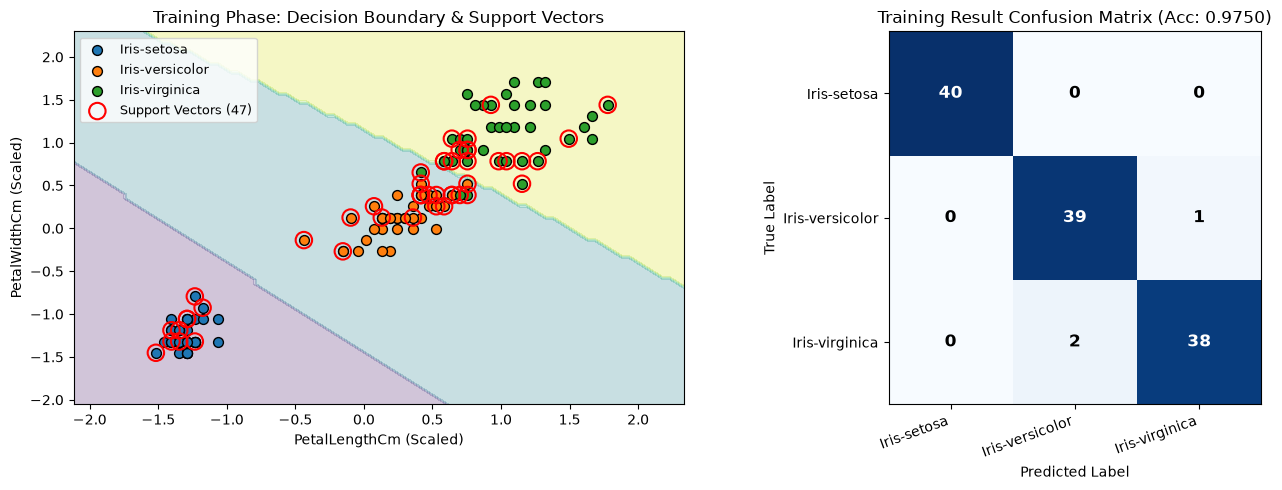

In [7]:
# แบ่งข้อมูลเป็นชุด Train (80%) และ Test (20%) โดยรักษาสัดส่วนของแต่ละคลาสให้เท่ากัน
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# ปรับสเกลข้อมูลให้มีค่าเฉลี่ย 0 และส่วนเบี่ยงเบนมาตรฐาน 1 (จำเป็นสำหรับ SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# สร้างโมเดล Support Vector Classifier (Single Model Baseline) พร้อมระบุพารามิเตอร์ชัดเจน
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

# ฝึกสอนโมเดลบนชุดข้อมูล Train และจับเวลาที่ใช้ในการเทรน
start_time = time.perf_counter()
svm_model.fit(X_train_scaled, y_train)
svm_train_time = time.perf_counter() - start_time

# ตรวจสอบผลลัพธ์สุดท้ายของการเทรนบนชุด Train
y_pred_train_svm = svm_model.predict(X_train_scaled)
svm_train_accuracy = accuracy_score(y_train, y_pred_train_svm)

print(f"Training Time: {svm_train_time:.4f} seconds")
print(f"Number of Support Vectors: {len(svm_model.support_vectors_)}")
print(f"Train Accuracy: {svm_train_accuracy:.4f}")

# แสดง Visualization ของขั้นตอนการเทรนและผลลัพธ์ชุด Train
plot_training_visualization(
    X_train_scaled=X_train_scaled,
    y_train=y_train,
    y_pred_train=y_pred_train_svm,
    model=svm_model,
    class_names=label_encoder.classes_
)

#### ขั้นตอนการ test

Test Accuracy: 0.9667

Test Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



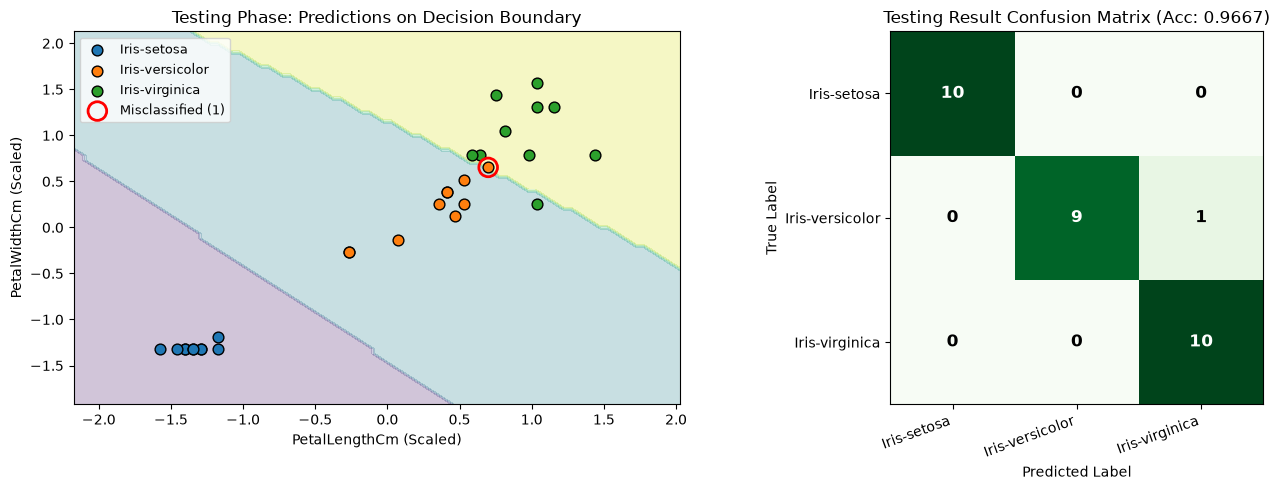

In [8]:
# นำโมเดลที่เทรนแล้วมาทำนายผลบนชุดข้อมูล Test
y_pred_test_svm = svm_model.predict(X_test_scaled)
svm_test_accuracy = accuracy_score(y_test, y_pred_test_svm)

print(f"Test Accuracy: {svm_test_accuracy:.4f}")
print("\nTest Classification Report:")
print(classification_report(y_test, y_pred_test_svm, target_names=label_encoder.classes_))

# แสดง Visualization ของผลลัพธ์การเทส
plot_testing_visualization(
    X_test_scaled=X_test_scaled,
    y_test=y_test,
    y_pred_test=y_pred_test_svm,
    model=svm_model,
    class_names=label_encoder.classes_
)

### Bagging

### Bosting